In [1]:
import numpy as np
import pandas as pd
import sklearn as sk
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

import os
import glob

In [2]:
if "get_ipython" not in globals() or "get_ipython" in globals() and get_ipython().__class__.__name__ == "TerminalInteractiveShell":
    matplotlib.use("Agg")

def plot(figsize=(6.4, 4.8), **kwargs):
    assert DATA_SUBSET != "test"

    plt.gcf().set_size_inches(*figsize)
    if "get_ipython" not in globals() or get_ipython().__class__.__name__ == "TerminalInteractiveShell":
        plt.savefig("a.png", **kwargs)
        plt.clf()
        plt.cla()
    else:
        plt.show()
    plt.close()

def dbg(x):
    print(x)
    return x

In [3]:
def load_split(pat):
    return pd.concat([
        pd.read_csv(
            dbg(name),
            dtype=dict(
                VendorID=int,
                passenger_count=float,
                trip_distance=float,
                RatecodeID="category",
                store_and_fwd_flag=str,
                PULocationID=int, # "category",
                DOLocationID=int, # "category",
                payment_type=int,
                fare_amount=float,
                extra=float,
                mta_tax=float,
                tip_amount=float,
                tolls_amount=float,
                improvement_surcharge=float,
                total_amount=float,
                congestion_surcharge=float,
                Airport_fee=float,
            ),
            parse_dates=[
                "tpep_pickup_datetime",
                "tpep_dropoff_datetime",
            ],
        )
        for name in sorted(glob.glob(f"../dataset-split/{pat}"))
    ], ignore_index=True)

In [4]:
zones = pd.read_csv("../dataset-split/taxi_zone_lookup.csv")
zones = set(zones[zones["Borough"] == "Manhattan"]["LocationID"])

In [5]:
# DATA_SUBSET = "sample"
DATA_SUBSET = "train"

# NOTE: **DO NOT USE FOR GENERATING GRAPHS**
# This is only allowed here so that the actual data cleaning does not
# have to be copied
# DATA_SUBSET = "test"

rides = load_split(f"{DATA_SUBSET}_*")
# rides = rides[rides["PULocationID"].isin(zones)]

../dataset-split/train_00.csv
../dataset-split/train_01.csv
../dataset-split/train_02.csv
../dataset-split/train_03.csv
../dataset-split/train_04.csv
../dataset-split/train_05.csv
../dataset-split/train_06.csv
../dataset-split/train_07.csv
../dataset-split/train_08.csv
../dataset-split/train_09.csv
../dataset-split/train_10.csv
../dataset-split/train_11.csv
../dataset-split/train_12.csv


In [6]:
rides.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


In [7]:
rides.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
count,2.763329e+07,27633290,27633290,2.496930e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.496930e+07,2.496930e+07
mean,1.764726e+00,2024-07-04 13:01:30.946711040,2024-07-04 13:16:37.325957120,1.330433e+00,3.641988e+00,1.682043e+02,1.650518e+02,1.101075e+00,1.571977e+01,1.239680e+00,4.829569e-01,2.825162e+00,2.347591e-01,9.708499e-01,2.333420e+01,2.365623e+00,1.396815e-04
min,1.000000e+00,2002-12-31 22:10:04,2002-12-31 22:14:22,0.000000e+00,0.000000e+00,4.000000e+00,1.000000e+00,0.000000e+00,-9.800000e+02,-7.500000e+00,-5.000000e-01,-3.000000e+02,-8.430000e+01,-1.000000e+00,-9.835000e+02,-2.500000e+00,-1.750000e+00
25%,2.000000e+00,2024-04-04 11:55:55.249999872,2024-04-04 12:12:46.249999872,1.000000e+00,9.800000e-01,1.370000e+02,1.140000e+02,1.000000e+00,8.600000e+00,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.540000e+01,2.500000e+00,0.000000e+00
50%,2.000000e+00,2024-06-30 16:08:00,2024-06-30 16:24:15,1.000000e+00,1.600000e+00,1.630000e+02,1.620000e+02,1.000000e+00,1.280000e+01,1.000000e+00,5.000000e-01,2.560000e+00,0.000000e+00,1.000000e+00,1.990000e+01,2.500000e+00,0.000000e+00
75%,2.000000e+00,2024-10-05 19:57:38,2024-10-05 20:13:12.500000,1.000000e+00,2.670000e+00,2.340000e+02,2.340000e+02,1.000000e+00,1.910000e+01,2.500000e+00,5.000000e-01,3.980000e+00,0.000000e+00,1.000000e+00,2.690000e+01,2.500000e+00,0.000000e+00
max,7.000000e+00,2026-06-26 23:53:12,2026-06-27 20:59:10,9.000000e+00,3.986086e+05,2.630000e+02,2.650000e+02,5.000000e+00,3.355444e+05,1.444000e+01,3.584000e+01,9.999900e+02,1.702880e+03,1.000000e+00,3.355509e+05,2.520000e+00,1.750000e+00
std,4.245956e-01,NaN,NaN,8.177385e-01,3.745468e+02,6.530407e+01,6.864552e+01,6.334606e-01,6.588833e+01,1.506391e+00,1.215137e-01,3.076578e+00,1.621543e+00,2.337268e-01,6.658820e+01,7.019455e-01,1.700921e-02


In [8]:
print(rides.isna().mean() * 100)

VendorID                 0.000000
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
passenger_count          9.640506
trip_distance            0.000000
RatecodeID               9.640506
store_and_fwd_flag       9.640506
PULocationID             0.000000
DOLocationID             0.000000
payment_type             0.000000
fare_amount              0.000000
extra                    0.000000
mta_tax                  0.000000
tip_amount               0.000000
tolls_amount             0.000000
improvement_surcharge    0.000000
total_amount             0.000000
congestion_surcharge     9.640506
Airport_fee              9.640506
dtype: float64


In [9]:
missing_by_vendor = (
    rides
    .groupby("VendorID")
    .agg(lambda x: x.isna().mean())
    * 100
).round(5)

missing_by_vendor = missing_by_vendor.loc[:, (missing_by_vendor > 0).any()]

print(missing_by_vendor)

          passenger_count  RatecodeID  store_and_fwd_flag  \
VendorID                                                    
1                 9.04186     9.04186             9.04186   
2                 9.82345     9.82345             9.82345   
6               100.00000   100.00000           100.00000   
7                 0.00000     0.00000             0.00000   

          congestion_surcharge  Airport_fee  
VendorID                                     
1                      9.04186      9.04186  
2                      9.82345      9.82345  
6                    100.00000    100.00000  
7                      0.00000      0.00000  


In [10]:
rides.info()

# Convert Y/N to boolean
rides['store_and_fwd_flag'] = (
    rides['store_and_fwd_flag']
    .map({'Y': True, 'N': False})
    .astype('boolean') # just for reference clarity
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27633290 entries, 0 to 27633289
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[ns]
 2   tpep_dropoff_datetime  datetime64[ns]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             object        
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee         

In [11]:
rides.dtypes

VendorID                          int64
tpep_pickup_datetime     datetime64[ns]
tpep_dropoff_datetime    datetime64[ns]
passenger_count                 float64
trip_distance                   float64
RatecodeID                       object
store_and_fwd_flag              boolean
PULocationID                      int64
DOLocationID                      int64
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
dtype: object


Add some computed features
* duration, in hours
* avg speed

Generally, this kind of thing should be part of feature engineering
but these features can indicate invalid data (eg. unrealistic speeds or negative
durations) and we'd like to remove
that as early as possible.

In [12]:
rides = rides.assign(
    duration_hours=lambda x:
        (
            x['tpep_dropoff_datetime'] - x['tpep_pickup_datetime']
        ).dt.total_seconds() / 3600,
).assign(
    avg_speed_mph=lambda x:
        x['trip_distance'] / x['duration_hours'].where(lambda x: x > 0),
    fare_per_hour=lambda x:
        x["fare_amount"] / x["duration_hours"].where(lambda x: x > 0),
)

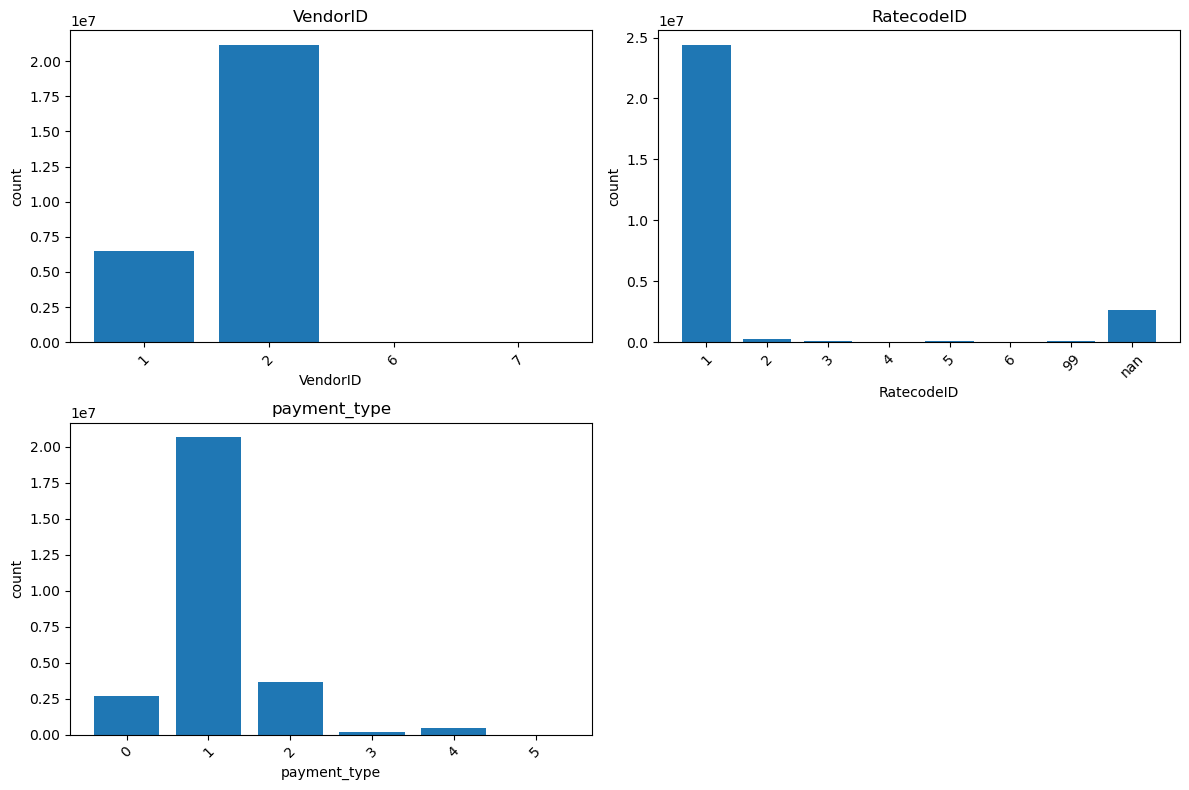

In [13]:
# https://stackoverflow.com/a/17511341
def ceildiv(a, b):
    return -(a // -b)

def nplots(n, cols):
    if DATA_SUBSET == "test":
        return None

    rows = ceildiv(n, cols)
    figsize=(6 * cols, 4 * rows)

    fig, axes = plt.subplots(rows, cols, figsize=figsize)

    for i, ax in enumerate(axes.flatten()):
        if i >= n:
            fig.delaxes(ax)
            continue

        yield i, ax

    plt.tight_layout()
    plot(figsize=figsize)


# label the cateogricals
raw_categorical = [
    "VendorID",
    "RatecodeID",
    "payment_type",
]

for i, ax in nplots(len(raw_categorical), 2):
    feature = raw_categorical[i]

    counts = rides[feature].value_counts(dropna=False).sort_index()
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("count")
    ax.tick_params(axis="x", rotation=45)

In [14]:
# check distributions of target variables of the target variables

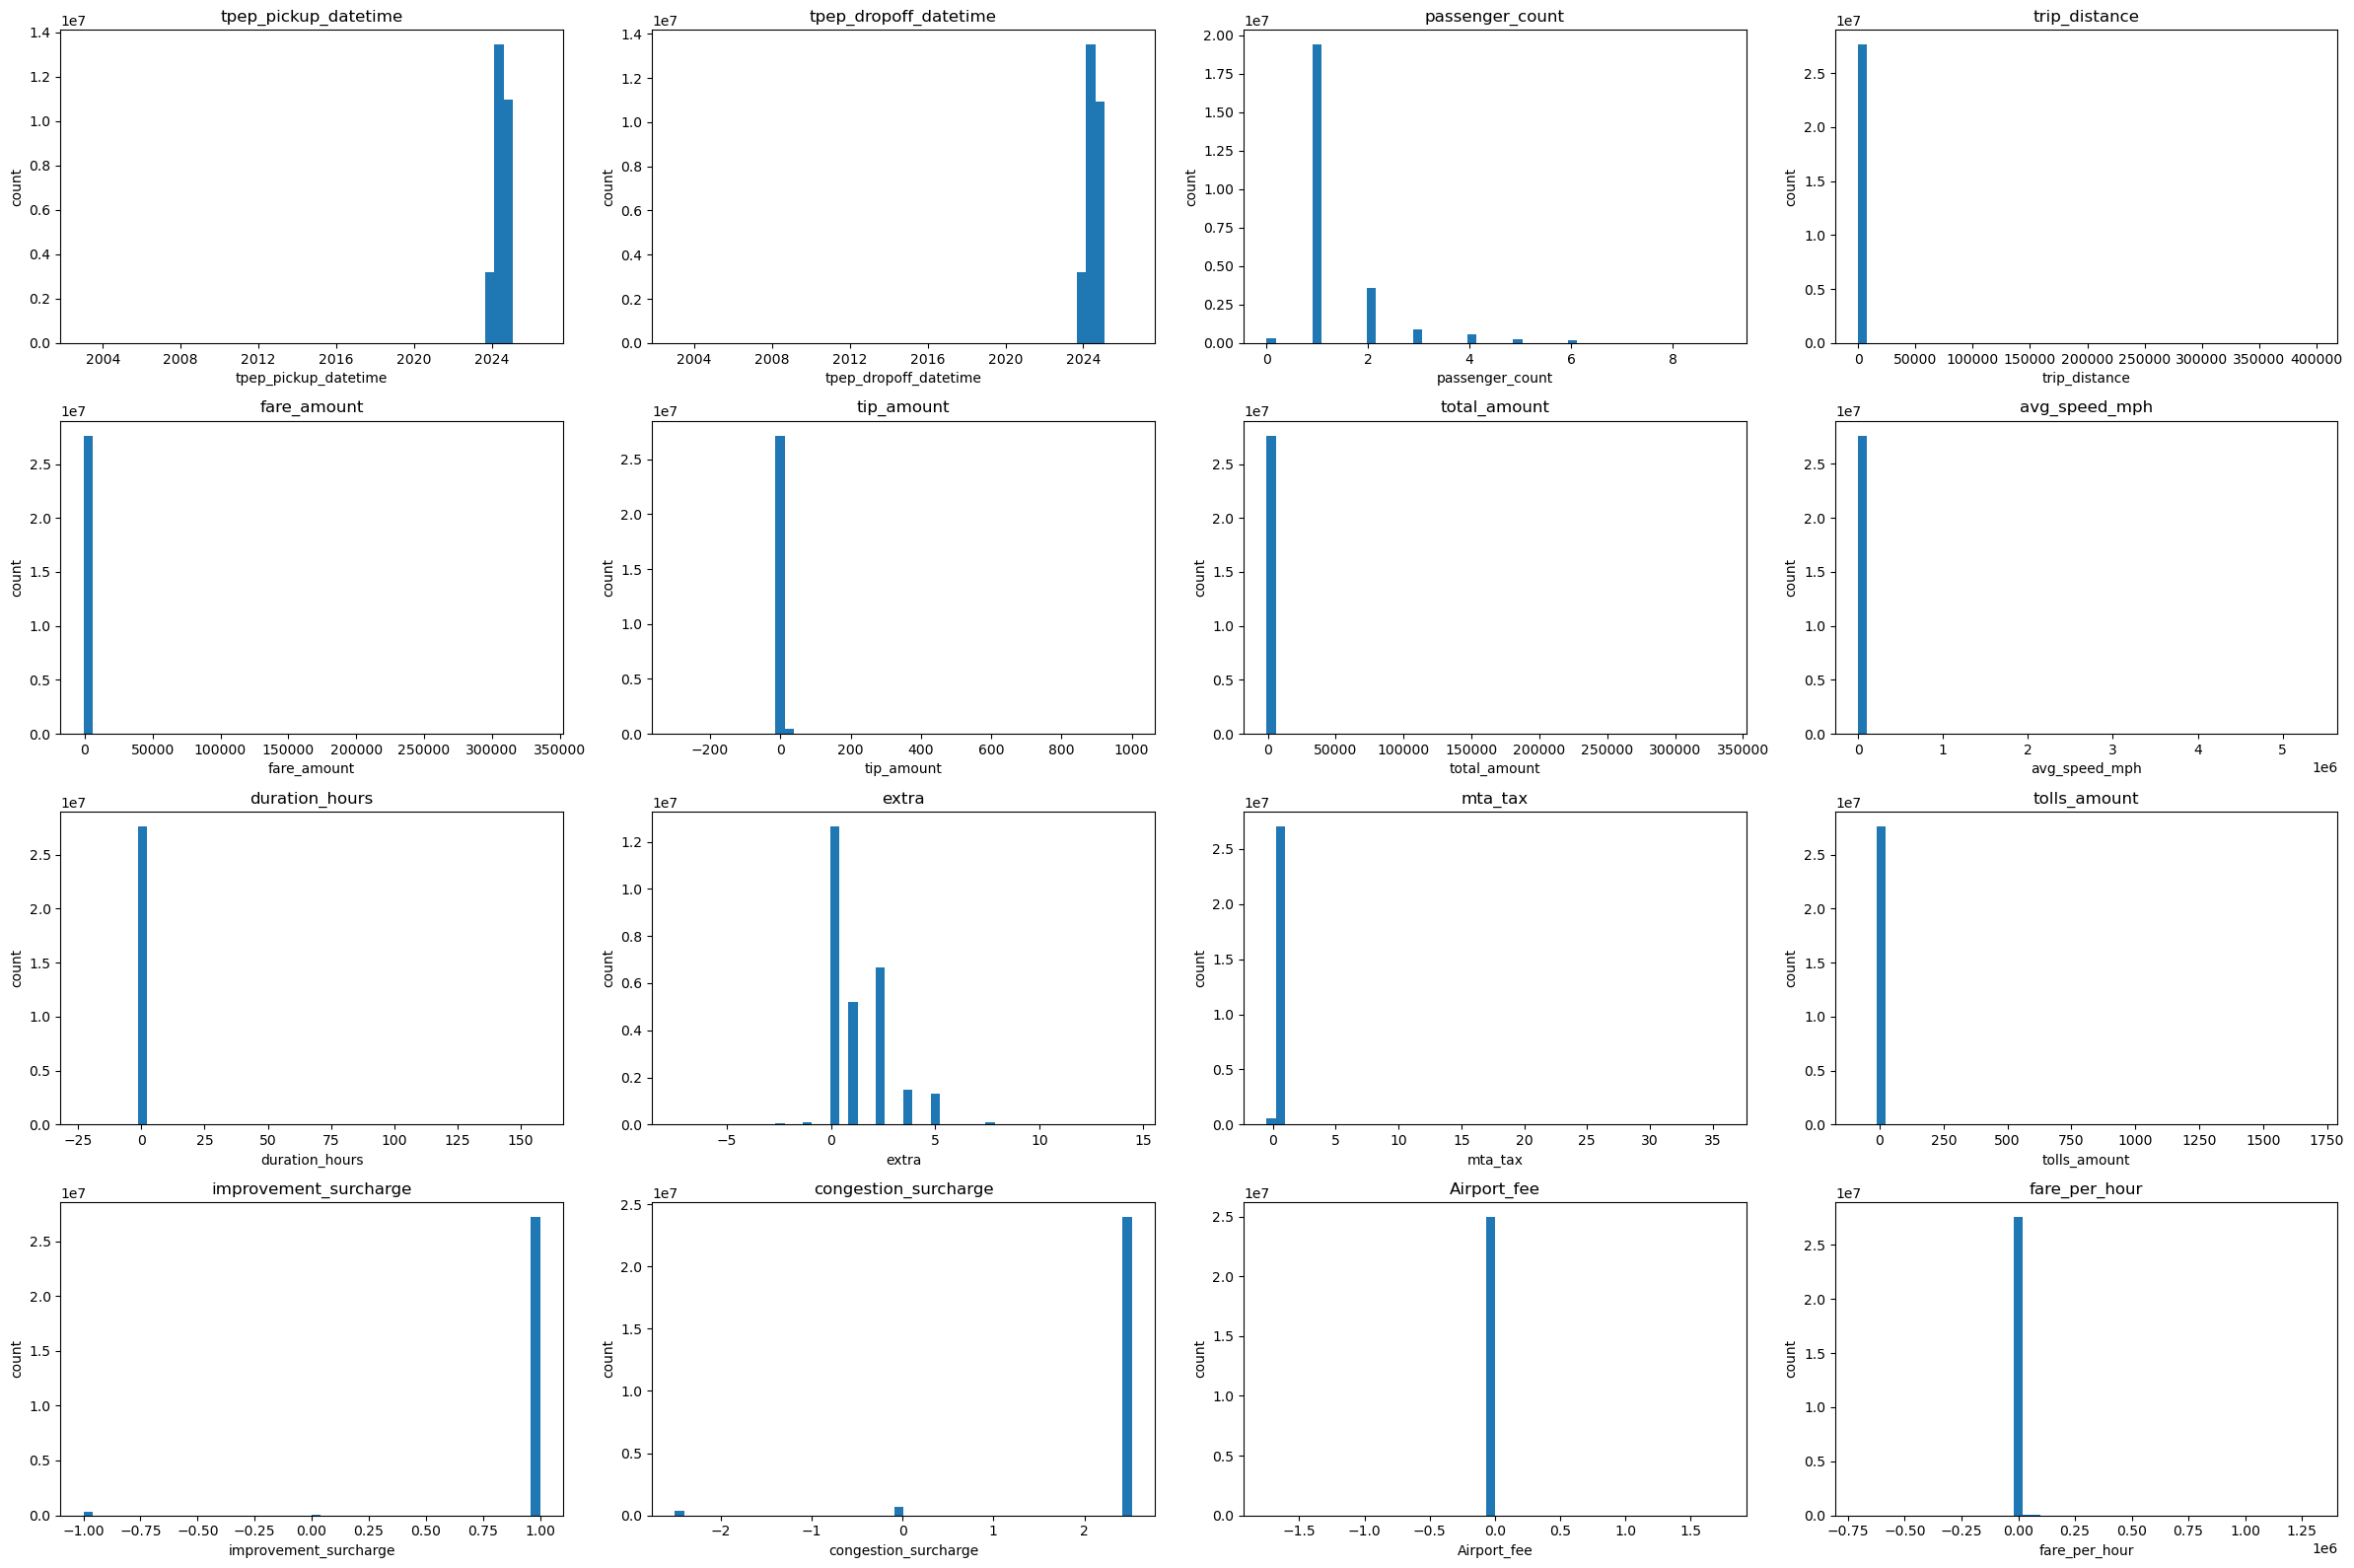

In [15]:
raw_numeric = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "avg_speed_mph",
    "duration_hours",
    "extra",
    "mta_tax",
    "tolls_amount",
    "improvement_surcharge",
    "congestion_surcharge",
    "Airport_fee",
    "fare_per_hour",
]

# Construct some binned histograms of the numerical variables so we can see the distribution and observe outliers.

for i, ax in nplots(len(raw_numeric), 4):
    feature = raw_numeric[i]
    ax.hist(rides[feature].dropna(), bins=50)
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("count")


Same but with log scale

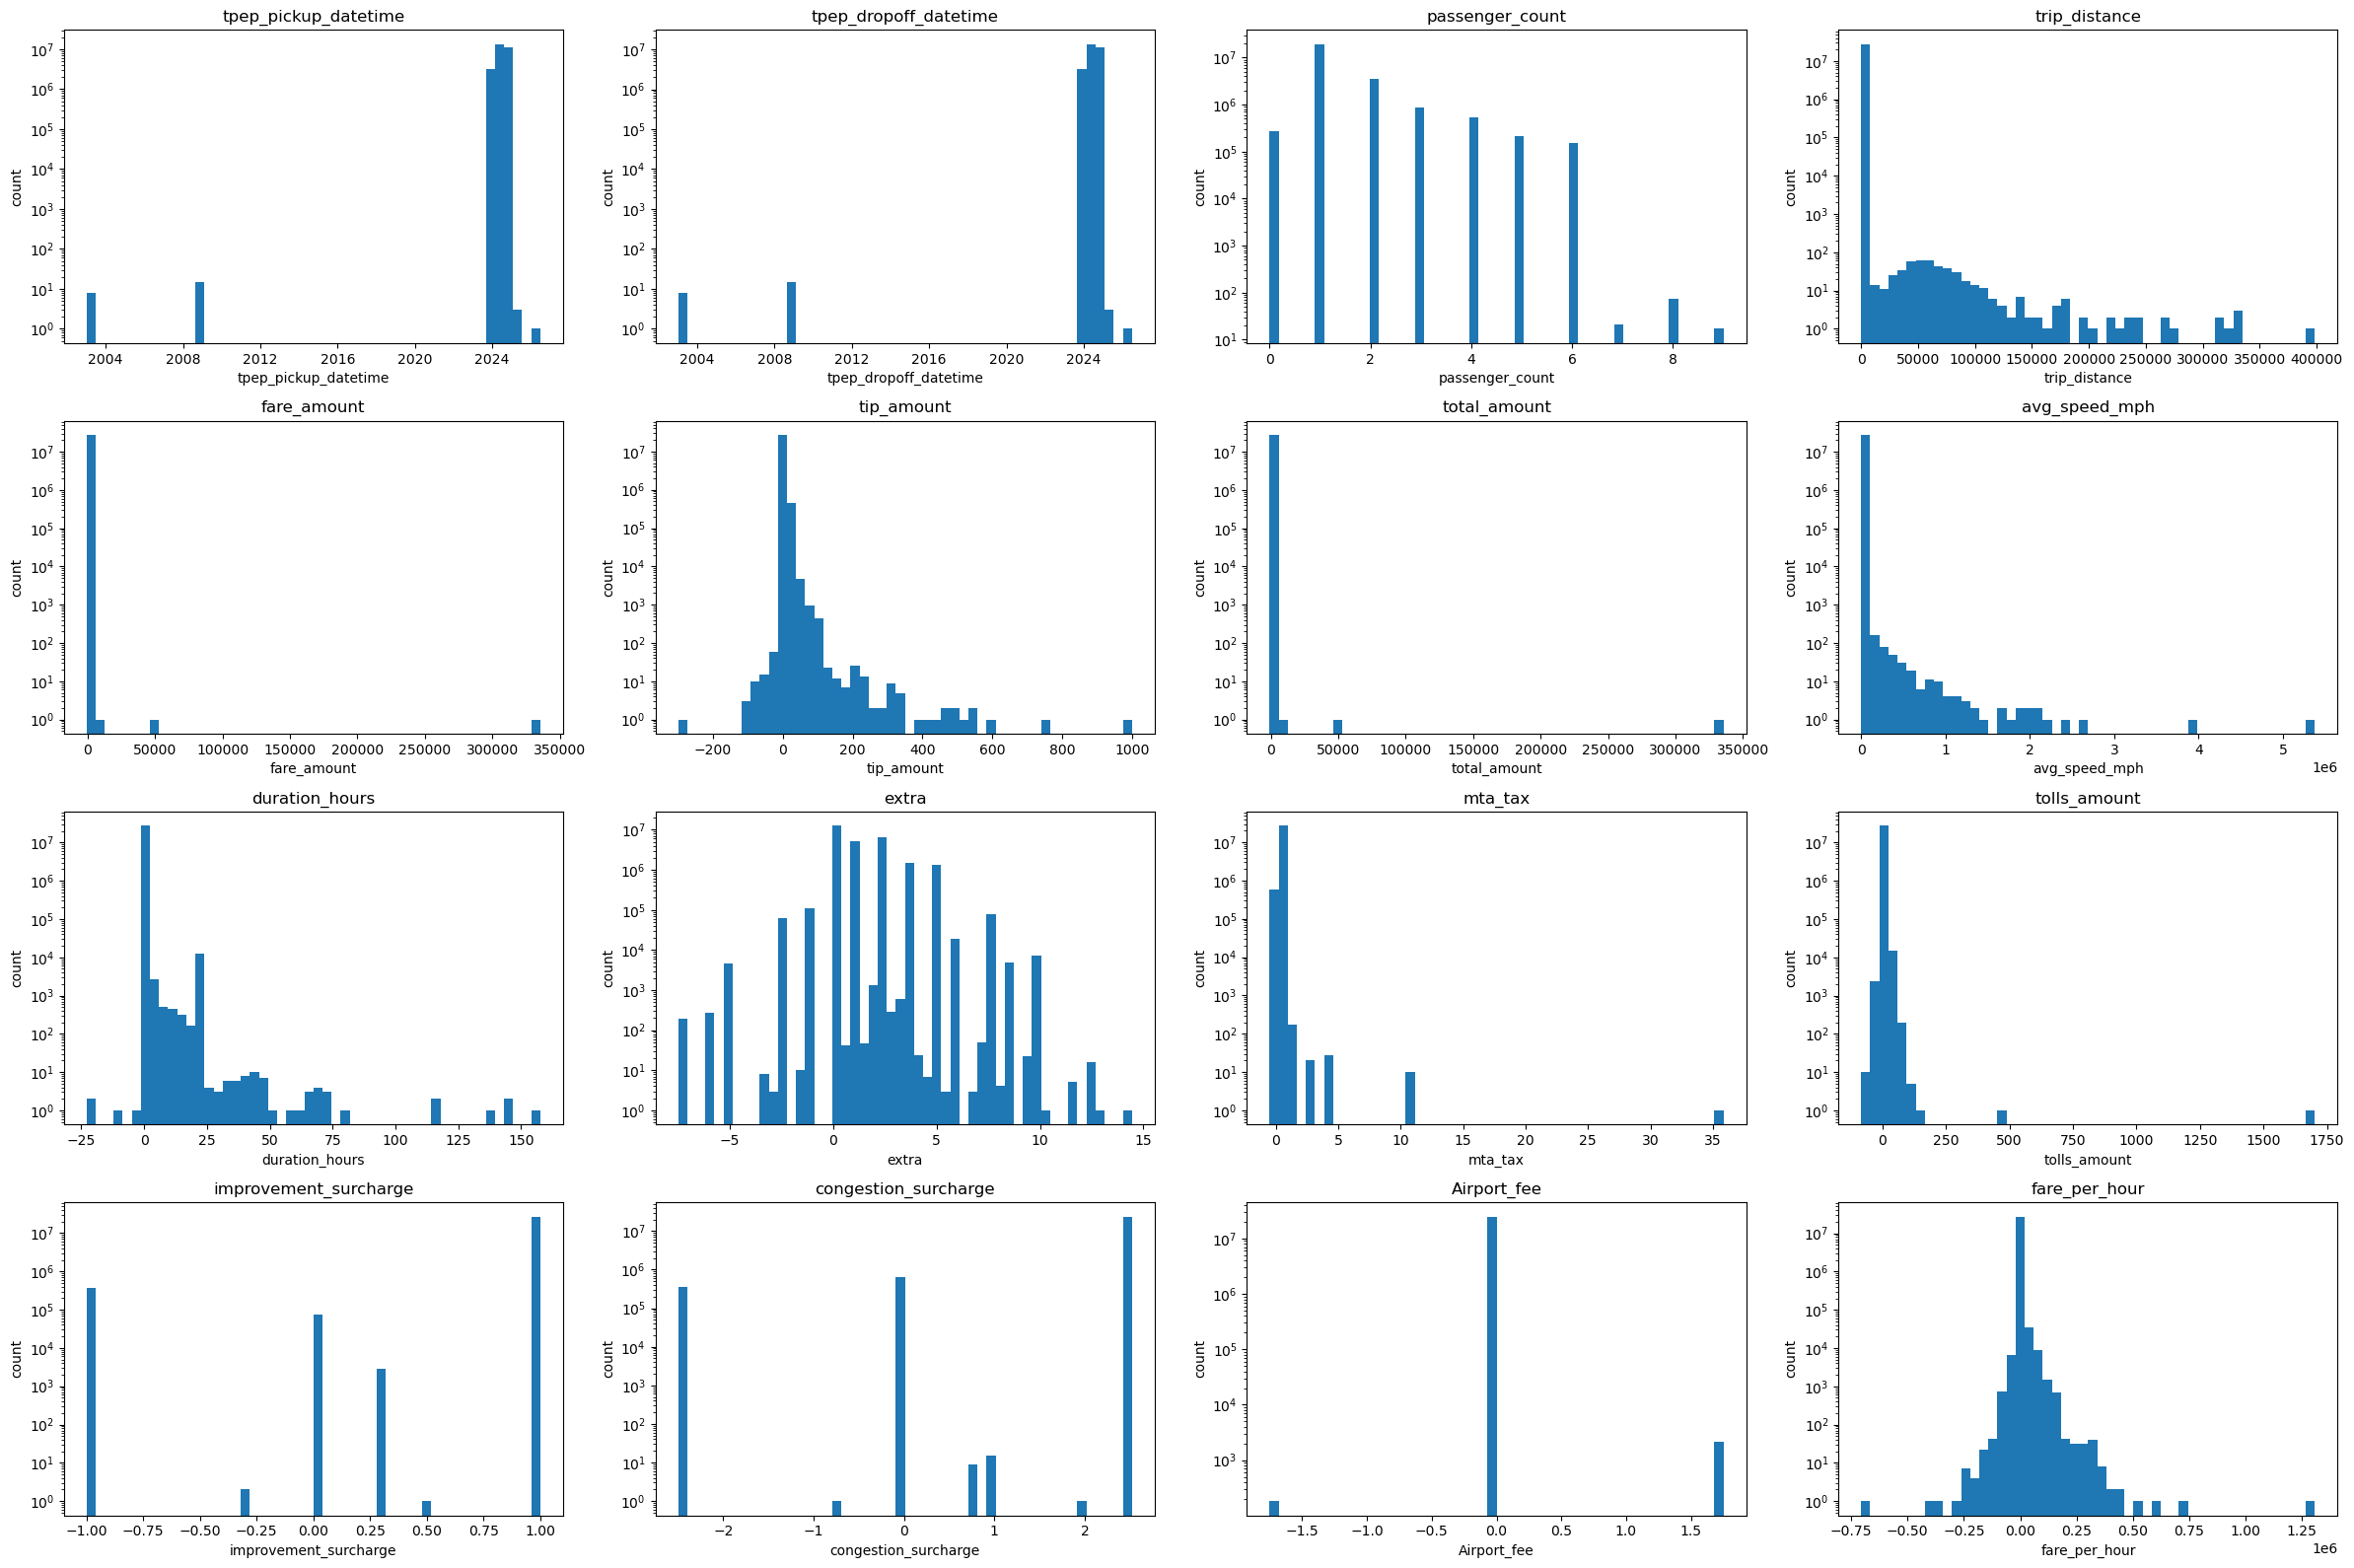

In [16]:
for i, ax in nplots(len(raw_numeric), 4):
    feature = raw_numeric[i]
    ax.hist(rides[feature].dropna(), bins=50, log=True)
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("count")

In [17]:
# Based on the above, we want to investigate trip_distance, fare_amount, mta_tax, total_amount, duration_hours, avg_speed_mph

# All negative values must be removed.

# Need to determine cut-off points for the others, to prevent enormous outliers from biasing the models.
# Below, we try some potential cut-offs and oberve ho

print("Counts of extreme / invalid values:\n")

checks = {
    "total_amount > 1000"  : ("total_amount"  , lambda x: x >  1000),
    "total_amount < 0.0"   : ("total_amount"  , lambda x: x <= 0.0),
    "avg_speed_mph > 150"  : ("avg_speed_mph" , lambda x: x >  150),
    "avg_speed_mph < 1"    : ("avg_speed_mph" , lambda x: x <  1),
    "duration_hours > 12"  : ("duration_hours", lambda x: x >  12),
    "duration_hours < 0.01": ("duration_hours", lambda x: x <  0.01),
}

for name, (col, condition) in checks.items():
    full_col = rides[col]
    flagged = full_col[condition(full_col)]
    count = len(flagged)

    if count > 0:
        # quantile position in the FULL distribution
        q_low = (full_col <= flagged.min()).mean()
        q_high = (full_col <= flagged.max()).mean()

        print(
            f"{name}: {count} | "
            f"value range: {flagged.min():.4f} to {flagged.max():.4f} | "
            f"full-sample quantile range: {q_low:.4f} to {q_high:.4f}"
        )
    else:
        print(f"{name}: {count}")

Counts of extreme / invalid values:

total_amount > 1000: 11 | value range: 1007.9800 to 335550.9400 | full-sample quantile range: 1.0000 to 1.0000
total_amount < 0.0: 368413 | value range: -983.5000 to 0.0000 | full-sample quantile range: 0.0000 to 0.0133
avg_speed_mph > 150: 4448 | value range: 150.6977 to 5379164.6000 | full-sample quantile range: 0.9996 to 0.9997
avg_speed_mph < 1: 484157 | value range: 0.0000 to 0.9997 | full-sample quantile range: 0.0153 to 0.0175
duration_hours > 12: 13123 | value range: 12.0172 to 157.5900 | full-sample quantile range: 0.9995 to 1.0000
duration_hours < 0.01: 191407 | value range: -22.9111 to 0.0097 | full-sample quantile range: 0.0000 to 0.0069


In [18]:
def get_constraint_violations(df, pad=1):

    violations = {}
    # These are the cut-offs we apply to the data. They are decided and refined using statistical assessment in 3.0 and checked using 3.2
    # The conditions describe what data will be flagged
    possible_checks = {
        'passenger_count': lambda x: x < 0,
        'trip_distance': lambda x: (x <= 0) | (x > 40 * pad), # to ensure the taxi actually moved
        'fare_amount': lambda x: (x < 0) | (x > 100 * pad),
        'fare_per_hour': lambda x: (x < 0) | (x > 1000 * pad),
        'extra': lambda x: x < 0,
        'mta_tax': lambda x: x < 0,
        'tip_amount': lambda x: (x < 0) | (x > 40 * pad),
        'tolls_amount': lambda x: (x < 0) | (x > 40 * pad),
        'improvement_surcharge': lambda x: x < 0,
        'total_amount': lambda x: (x < 0) | (x > 250 * pad),
        'congestion_surcharge': lambda x: x < 0,
        'Airport_fee': lambda x: x < 0,
        'duration_hours': lambda x: (x < 0.01) | (x > 2 * pad), # to remove any entries which took zero time
        'avg_speed_mph': lambda x: (x <= 0) | (x > 40 * pad), # to remove any entries which suggest the taxi has moved unrealistically far in a given time.
        'tpep_pickup_datetime': lambda x: (x < "2024-01-01") | (x >= "2025-01-01")
    }

    # Column-based checks
    for col, condition in possible_checks.items():
        if col in df.columns:
            mask = condition(df[col])
            violations[col] = df.index[mask].tolist()

    # Datetime check
    if 'tpep_pickup_datetime' in df.columns and 'tpep_dropoff_datetime' in df.columns:
        mask = df['tpep_dropoff_datetime'] < df['tpep_pickup_datetime']
        violations['pickup_before_dropoff'] = df.index[mask].tolist()

    # Combine all violating indices
    all_bad_indices = set()
    for v in violations.values():
        all_bad_indices.update(v)

    return violations, all_bad_indices

# ##

# clean the dataset for real now

# Get the violation df and the row numbers of offending data entries
violations, bad_idx = get_constraint_violations(rides)
rides_clean = rides.drop(index=bad_idx)

# Print a summary in order to check how much is flagged. We want this to be relatively small compared to sample size.
pad = max(len(v) for v in violations.keys())
print(f"{"violation":<{pad + 1}}count")
for k, v in violations.items():
    print(f"{k:<{pad + 1}}{len(v)}")
print(f"Total bad rows: {len(bad_idx)}")
print(f"Ratio bad rows: {len(bad_idx) / len(rides)}")

violation             count
passenger_count       0
trip_distance         430532
fare_amount           483934
fare_per_hour         580123
extra                 177440
mta_tax               355236
tip_amount            5313
tolls_amount          11794
improvement_surcharge 364068
total_amount          367709
congestion_surcharge  349260
Airport_fee           183
duration_hours        210771
avg_speed_mph         448402
tpep_pickup_datetime  37
pickup_before_dropoff 1033
Total bad rows: 968968
Ratio bad rows: 0.035065241959969295


Total bad rows: 906638
Ratio bad rows: 0.03280962925514841


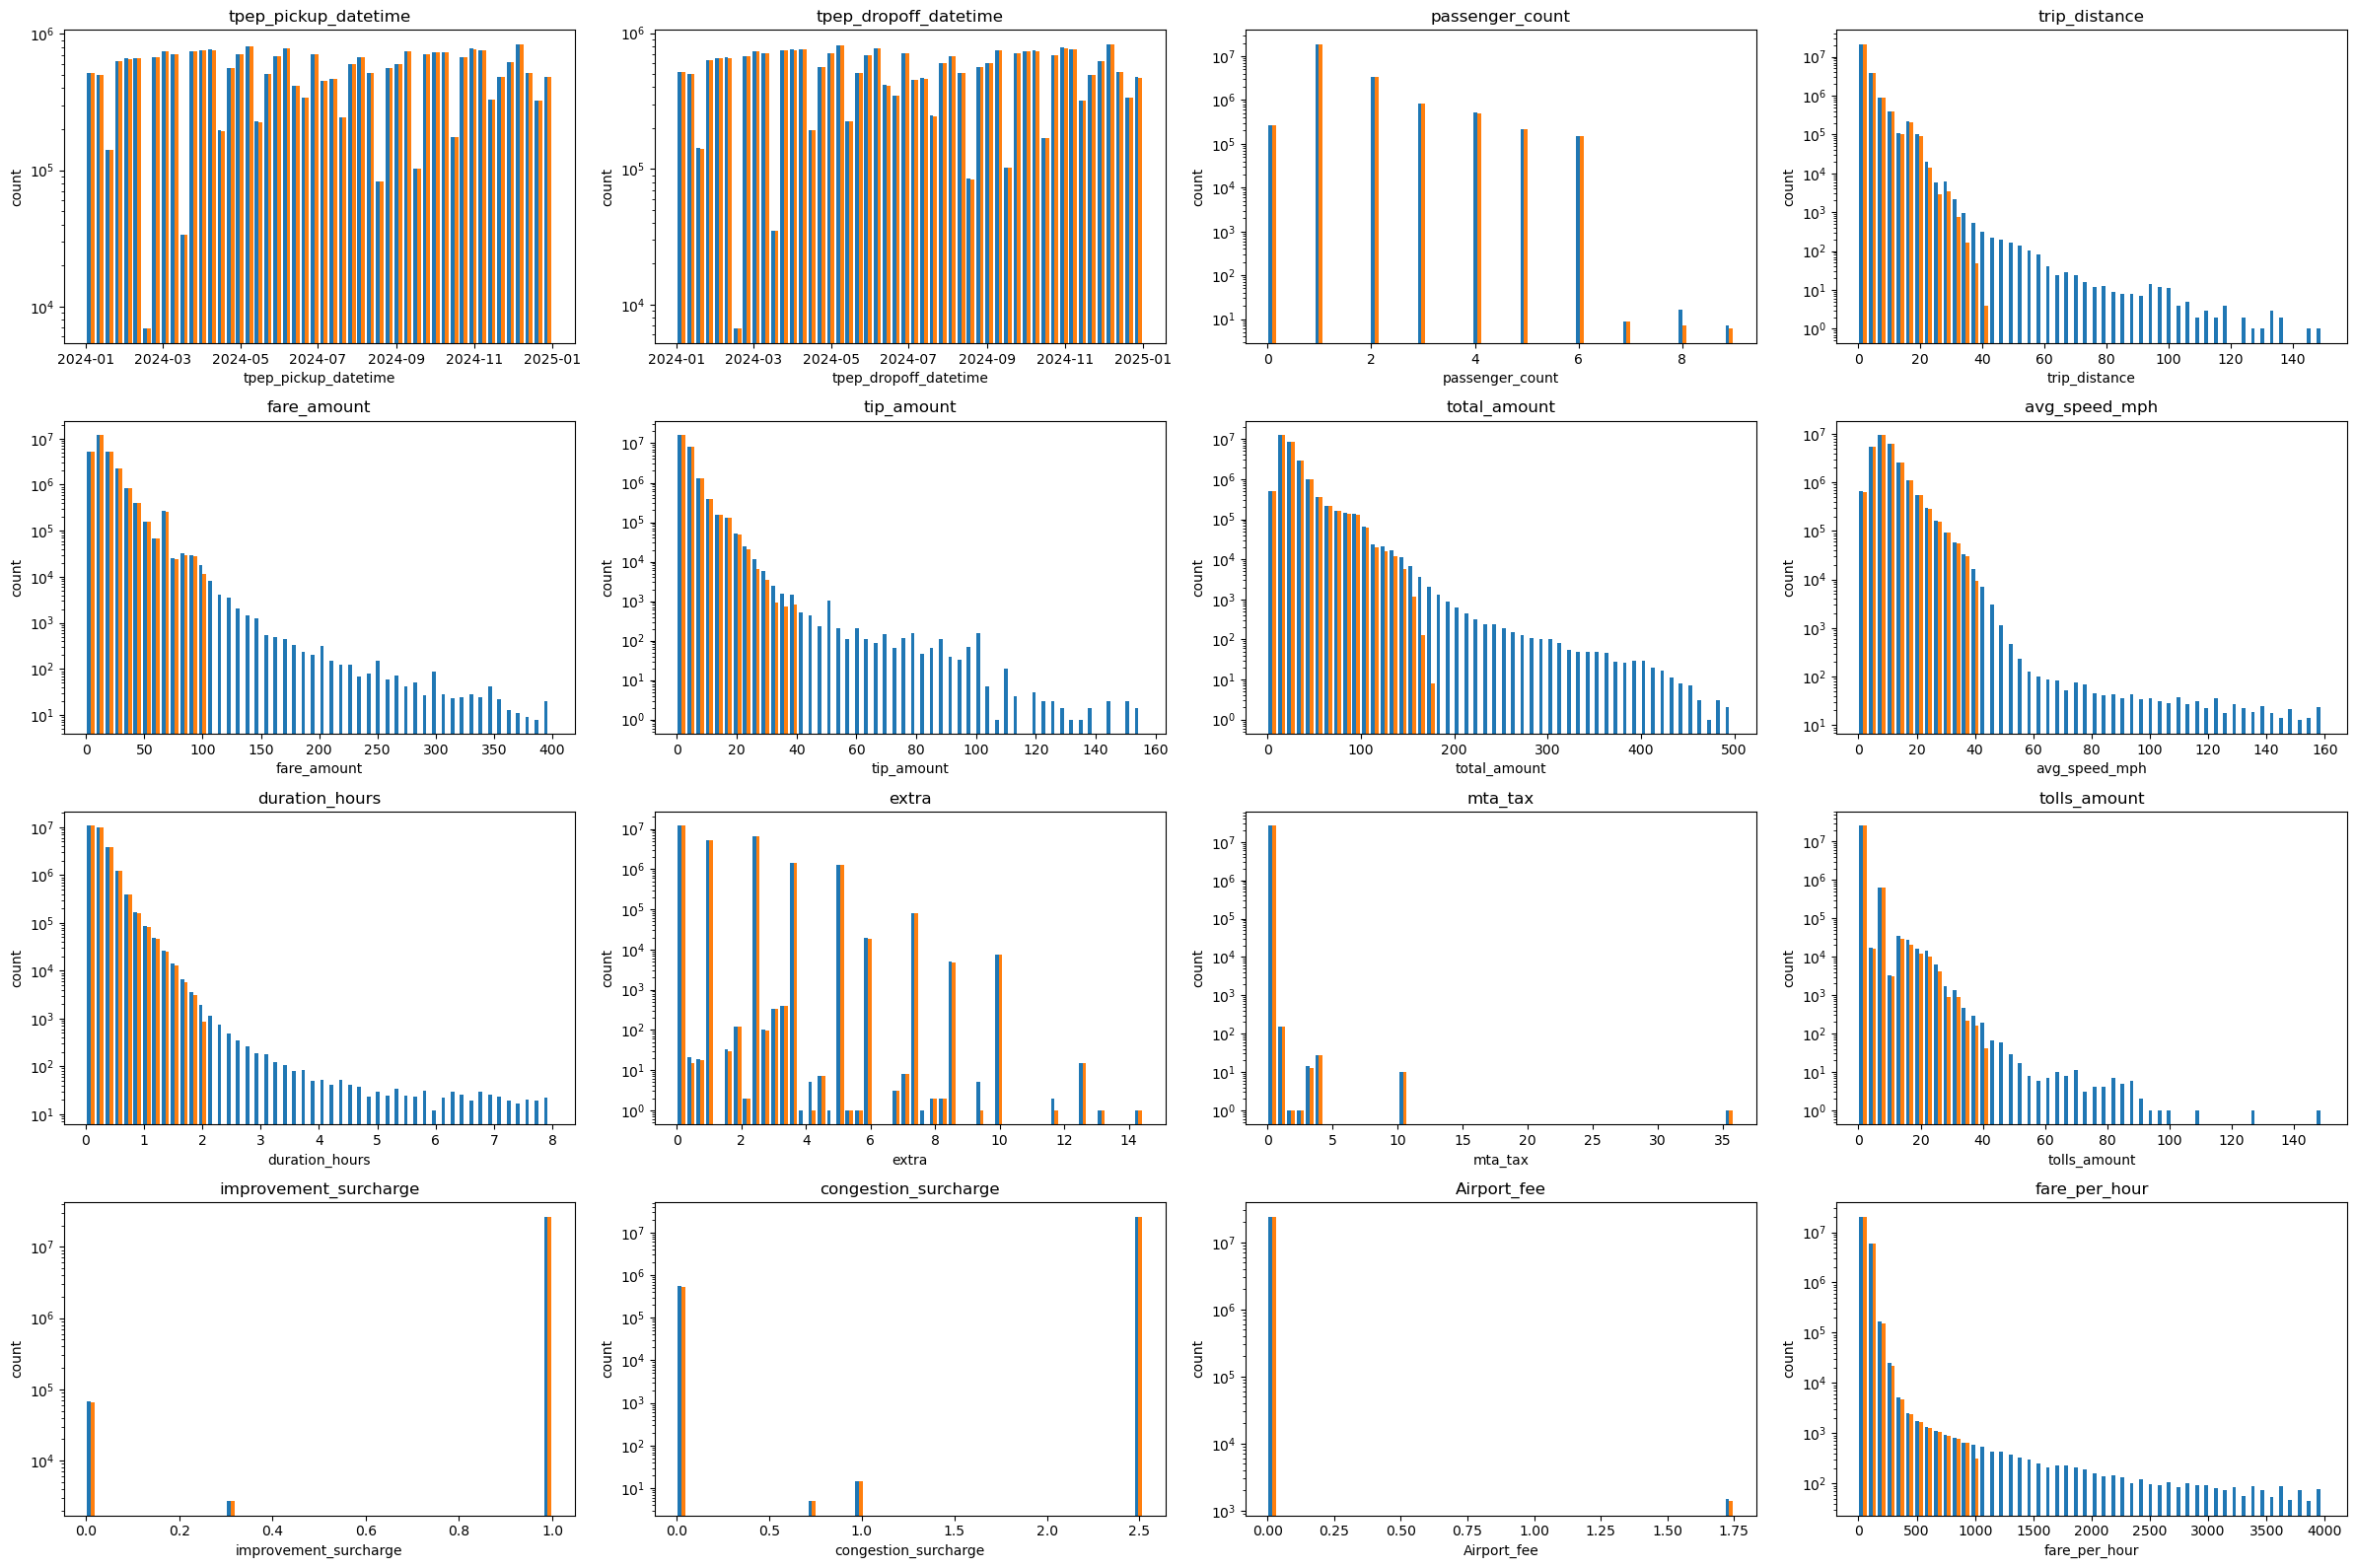

In [19]:
# plot with padding to see the edges of what's being removed
# pad multiplies upper bound of gamma-distributed variables by 4

_, bad_idx_pad = get_constraint_violations(rides, pad=4)
print(f"Total bad rows: {len(bad_idx_pad)}")
print(f"Ratio bad rows: {len(bad_idx_pad) / len(rides)}")
rides_pad = rides.drop(index=bad_idx_pad)

for i, ax in nplots(len(raw_numeric), 4):
    feature = raw_numeric[i]
    ax.hist(
        [
            rides_pad[feature].dropna(),
            rides_clean[feature].dropna(),
        ],
        label=["upper bound x4", "upper bound"],
        bins=50,
        log=True,
    )
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("count")


The above graph looks extreme, but it is in log scale. In a linear scale
it looks more appropriate. More dat is often better, but these variables
have very long tails which can throw off mechanisms like scaling and makes
learning correlations difficult.

Future work would be to try to non-linearly compress the outlying values
instead of throwing them out entirely.

All things considered, the discarded data is <3% of the training data

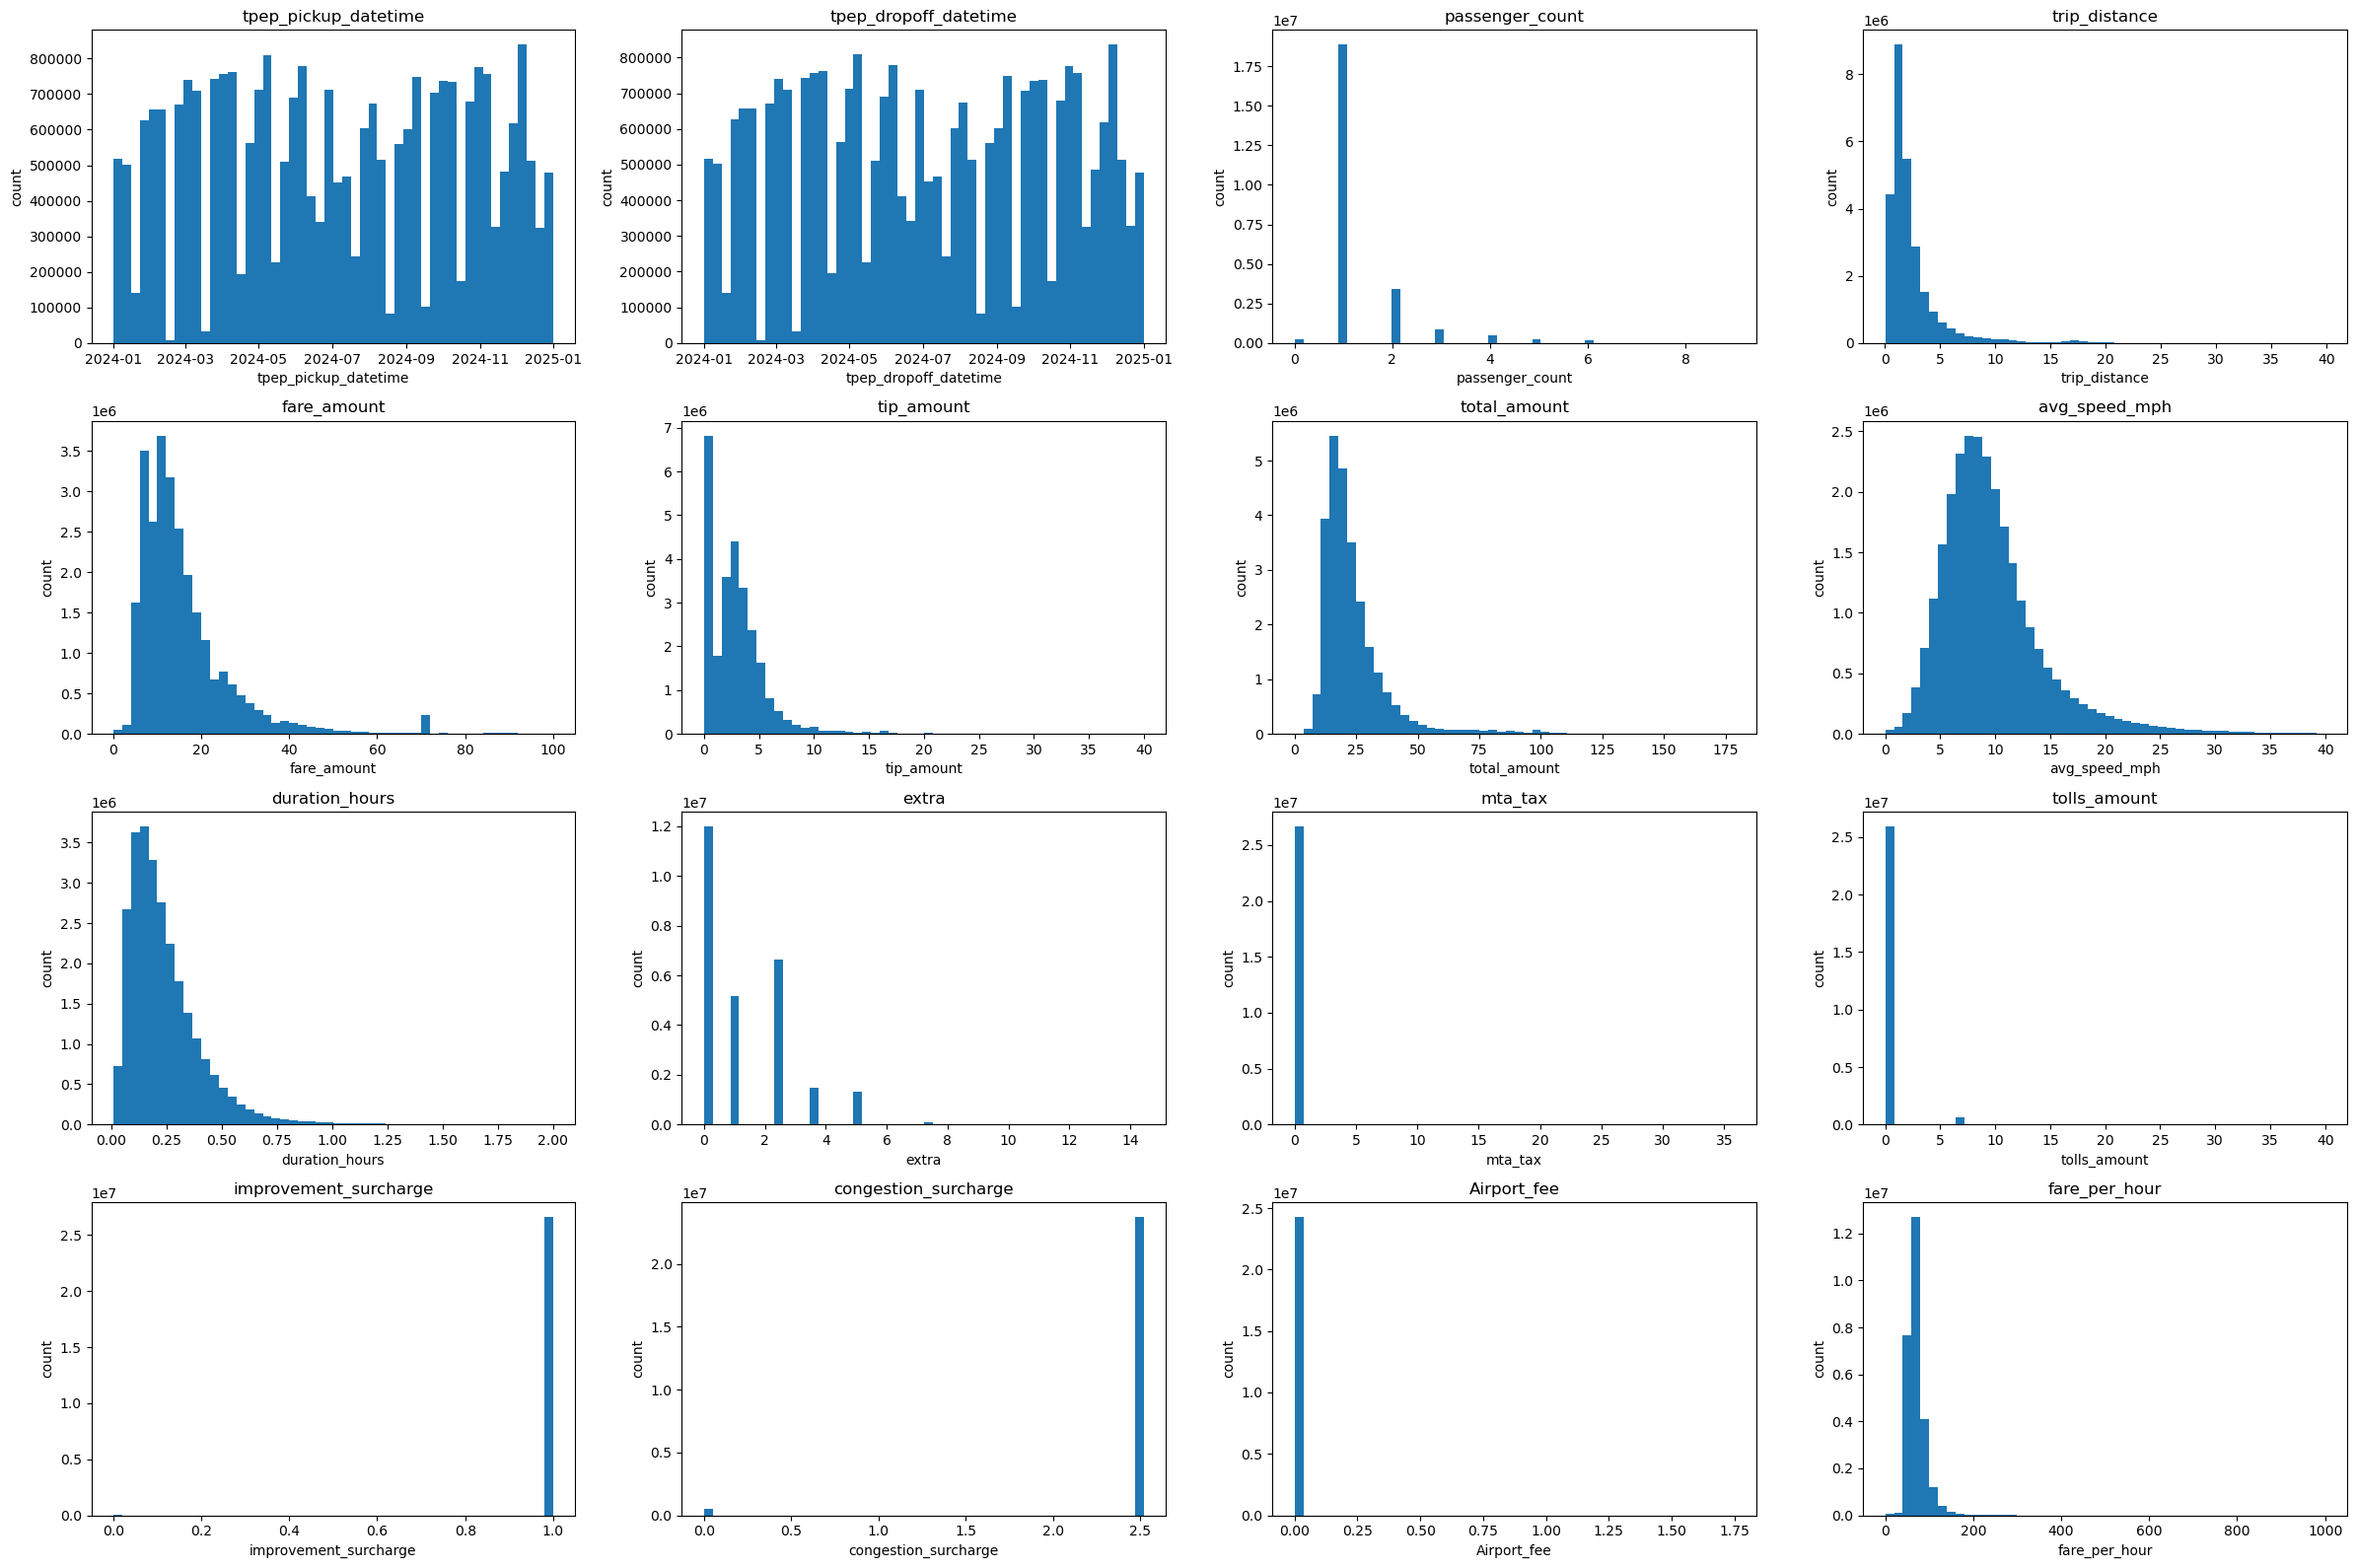

In [20]:
for i, ax in nplots(len(raw_numeric), 4):
    feature = raw_numeric[i]
    ax.hist(rides_clean[feature].dropna(), bins=50)
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("count")

In [21]:
rides_clean.dtypes
rides_clean.shape

(26664322, 22)

In [ ]:
def save_split(df, prefix, rows_per_file=1800000):
    for i in range(0, ceildiv(len(df), rows_per_file)):
        df[i*rows_per_file:(i+1)*rows_per_file].to_csv(dbg(f"{prefix}_{i:02}.csv"), index=False)

save_split(
    rides_clean.sort_values("tpep_pickup_datetime"),
    f"../dataset-clean/{DATA_SUBSET}",
)